# Magnetic Fields in MRI

**Part:** B — Hardware · **Reading time:** ~60 min · **Pass 1 overview:** [The MRI Scanner](../pass1_big_picture/P1.2_The_MRI_Scanner.ipynb) · **Refreshers you may want:** [Magnetism from currents (Biot–Savart, loops, solenoids)](../refreshers/RP1_Magnetism_from_Currents.ipynb), [Induction and RF (Faraday, resonance, reciprocity)](../refreshers/RP2_Induction_and_RF.ipynb), [Complex numbers and rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

The magnetic fields created and manipulated during an MRI experiment determine everything that follows: how strongly spins are polarized, at which frequency they precess, how they are tipped, how their position is encoded, and how their signal is picked up. In this chapter we compute these fields ourselves from the currents that create them (with the Biot–Savart law), see *why* MRI coils have the shapes they have (solenoid, Maxwell pair, saddle coil, birdcage, surface loop), and quantify the requirements (ppm homogeneity, gradient linearity, RF polarization). The engineering of each coil type is continued in [B3](B3_Main_Magnet_Engineering.ipynb) (magnet), [B4](B4_Gradient_System_Engineering.ipynb) (gradients) and [B5](B5_RF_System_and_Receive_Chain.ipynb) (RF).

## Learning goals

1. Describe the fundamental components of an MRI scanner and why they are necessary
    * Define the magnetic fields created by the various components (direction, magnitude, frequency)
    * Describe the purpose of each magnetic field
2. Understand what MRI is measuring
    * Describe how RF coils receive the MRI signal (induction, reciprocity)
3. *(new)* Compute the field of loops and solenoids with the Biot–Savart law, and explain why the main magnet must be homogeneous to a few ppm.
4. *(new)* Explain how a Maxwell pair creates $G_z$ and how saddle (Golay) coils create $G_x$, $G_y$; know what concomitant (Maxwell) fields are.
5. *(new)* Compare surface-loop and birdcage RF coils; explain linear vs circular polarization, why only the co-rotating component $B_1^+$ tips spins, and why quadrature drive halves the RF power.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$ | position; $z$ along the bore / $B_0$ | m | |
| $\rho$, $\varphi$ | cylindrical radius $\sqrt{x^2+y^2}$ and azimuthal angle | m, rad | |
| $t$ | time | s | |
| $\vec B(\vec r,t)=[B_x,B_y,B_z]^T$ | magnetic flux density ("magnetic field") | T | 1 T = 10 000 gauss |
| $B_0$ | main static field (along $z$) | T | 1.5, 3 T |
| $\Delta B_0(\vec r)$ | deviation from $B_0$ (inhomogeneity) | T | ppm of $B_0$ |
| ppm | parts per million ($10^{-6}$, relative) | – | 1 ppm of 3 T = 3 µT ↔ 127.7 Hz |
| DSV | "diameter of spherical volume" over which homogeneity is specified | m | 0.4–0.5 m |
| $\vec G=[G_x,G_y,G_z]^T$ | gradient of $B_z$ | T/m | 10–80 mT/m |
| $B_1(t)$; $B_{1,X}, B_{1,Y}$ | RF field amplitude; its components in the rotating frame | T | 1–25 µT |
| $B_1^+(\vec r)$ | co-rotating (spin-tipping) RF component | T (or T/A per unit current) | |
| $B_1^-(\vec r)$ | counter-rotating component = receive sensitivity by reciprocity | T/A | ~µT/A |
| $\tilde B_x,\tilde B_y$ | complex phasor amplitudes of a field oscillating at $\omega$ | T | |
| $\vec M$, $M_0$, $M_{xy}$ | magnetization; equilibrium value; transverse part | A/m | water at 3 T: $M_0\approx 9\times10^{-3}$ A/m |
| $\vec m$ | magnetic moment of a voxel, $\vec M\cdot V$ | A m² | |
| $V$ | volume | m³ | 1 mm³ = $10^{-9}$ m³ |
| $I_c$ | current in a coil (we avoid $I$, which is the spin quantum number) | A | |
| $R_c$ | radius of a loop or coil | m | |
| $n$ | number of turns per metre of a solenoid (in §3) / element index (in §6) | 1/m / – | |
| $L_s$ | length of a solenoid | m | |
| $d\vec\ell$ | short vector piece of wire along the current | m | |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $\gamma$, $\bar\gamma$ | gyromagnetic ratio (rad s⁻¹ T⁻¹), gamma-bar (Hz/T) | | 42.58 MHz/T |
| $\omega_0=2\pi f_0$, $f_0=\bar\gamma B_0$ | Larmor angular frequency / frequency | rad/s, Hz | 127.7 MHz at 3 T |
| $\Delta f$ | frequency offset | Hz | |
| $\Phi$ | magnetic flux through a coil (in §5; elsewhere $\phi$ is phase) | Wb = T m² | |
| $\mathcal E$ | induced voltage (EMF) | V | |
| $BW_{pix}$ | receiver bandwidth per pixel | Hz | 100–500 Hz |
| $\Delta x$ | displacement (distortion) in the image | m | |
| $P$ | RF power | W | |
| $C_n(\vec r)$ | complex sensitivity of receive element $n$ (∝ $B_{1,n}^-$) | – | |

> **⚠️ Common confusion:** the original uses "$B_1^-$" both for a *field* (in the summary table, "≈10 nT") and for a *sensitivity* (in T/A). In this course $B_1^-$ is the **receive sensitivity** (field per unit current, T/A); the field produced by the magnetization itself is written $\mu_0\vec M$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Summary of magnetic fields

Each of the main components of an MRI system creates a magnetic field, but with different orientations, magnitudes and frequencies:

| Component | Notation | Field direction | Frequency | Strength | Purpose |
| --- | --- | --- | --- | --- | --- |
| Main field | $B_0$ | $z$ | 0 Hz (static) | 0.55–7 T (≈1 T order) | polarization |
| Main field inhomogeneities | $\Delta B_0(\vec{r})$ | $z$ | 0 Hz | ≈ 0.1–10 ppm of $B_0$ | – (unwanted) |
| Magnetic field gradients | $\vec G(t)$ | $z$ (the *variation* is along $x$, $y$ or $z$) | ≈ 1 kHz (0.1–10 kHz) | ≈ 10–80 mT/m, i.e. ≈ 10 mT at the edge of the FOV | spatial encoding |
| Transmit RF coils | $B_1^+(\vec{r},t)$ | $x,y$ (rotating) | ≈ 100 MHz ($f_0$) | ≈ 10 µT | excitation |
| Receive RF coils | $B_1^-(\vec{r})$ | $x,y$ | ≈ 100 MHz ($f_0$) | sensitivity ≈ µT per A | reception |
| Net magnetization | $\vec{M}(\vec{r},t)$ | $x,y,z$ | ≈ 100 MHz (precession) | $\mu_0 M_0$ ≈ 10 nT (water, 3 T) | signal source |

The net magnetization, $\vec{M}(\vec{r},t)$, is included because it is itself a (tiny) magnetic field source: it is what we measure.

> **📐 Math note (corrections to the original table):** gradients have units of T/m (the original wrote "mT"); the field produced by water magnetization is ≈ 10 nT at 3 T, not ≈ 1 pT (we compute it below); the receive coil is described by a sensitivity in T/A rather than a field.

In [2]:
# The field created by the magnetization of water at body temperature (derivation in A1 Spin Physics)
N_H, T_body = 6.7e28, 310.0          # 1H density of water [1/m^3], body temperature [K]
for B0 in [1.5, 3.0, 7.0]:
    M0 = N_H * (mt.GAMMA * mt.HBAR) ** 2 * B0 / (4 * mt.K_BOLTZMANN * T_body)   # [A/m]
    print(f"B0 = {B0} T: M0 = {M0:.2e} A/m, mu0*M0 = {mt.MU0*M0*1e9:5.1f} nT  (= {mt.MU0*M0/B0*1e9:.1f} ppb of B0)")

B0 = 1.5 T: M0 = 4.67e-03 A/m, mu0*M0 =   5.9 nT  (= 3.9 ppb of B0)
B0 = 3.0 T: M0 = 9.34e-03 A/m, mu0*M0 =  11.7 nT  (= 3.9 ppb of B0)
B0 = 7.0 T: M0 = 2.18e-02 A/m, mu0*M0 =  27.4 nT  (= 3.9 ppb of B0)


*Interpretation:* the magnetization is ~4 parts per billion of the applied field. We can only detect it because, after excitation, it **precesses** at a precisely known frequency and induces a voltage in a tuned coil.

## 2. Loop currents and magnetic fields

Magnetic fields, $\vec{B}$, are created by electric currents, governed by Maxwell's equations of electromagnetism. A current $I_c$ through a loop of wire creates a field that circles around the wire and points through the loop. Its direction follows the **right-hand rule**: curl the fingers of your right hand in the direction of the (conventional) current; your thumb points along $\vec B$ inside the loop. (The original text says "left-hand rule" — that is incorrect for conventional current.)

![Field of a loop with a small current](../images/loop_small_current.png)

*Field lines of a current loop (cross-section). The field is strongest near the wire and points through the loop.*

Increasing the current increases the field proportionally:

![Field of a loop with a large current](../images/loop_big_current.png)

*Same loop with a larger current: same field shape, larger magnitude ($\vec B \propto I_c$).*

### 2.1 The Biot–Savart law

To compute the field of any wire shape we add up the contributions of many short pieces of wire ([refresher](../refreshers/RP1_Magnetism_from_Currents.ipynb)):

$$d\vec B(\vec r) = \frac{\mu_0 I_c}{4\pi}\,\frac{d\vec\ell\times(\vec r-\vec r\,')}{|\vec r-\vec r\,'|^3}$$

*In words:* each short piece of wire contributes a field that is proportional to the current, perpendicular both to the wire and to the line joining the wire to the observation point, and that falls off like 1/distance².
where $d\vec B$ = field contribution [T], $\mu_0=4\pi\times10^{-7}$ T m/A, $I_c$ = current [A], $d\vec\ell$ = vector along the wire piece in the direction of the current [m], $\vec r\,'$ = position of the wire piece [m], $\vec r$ = observation point [m], $\times$ = cross product.

The total field is the sum (integral) over the whole wire. Fields of several coils simply **add** (superposition). `mt.loop_coil_field` does exactly this sum for a circle cut into straight segments.

For the special case of a point on the axis of a circular loop of radius $R_c$, the integral can be done by hand:

$$B_z(z) = \frac{\mu_0 I_c R_c^2}{2\,(R_c^2+z^2)^{3/2}}, \qquad B_z(0)=\frac{\mu_0 I_c}{2R_c}$$

*In words:* on the axis the field points along the axis, is largest at the loop's center, and falls off like $1/z^3$ far away (the loop then looks like a small magnetic dipole).
where $z$ = distance from the loop plane along its axis [m], $R_c$ = loop radius [m].

<details><summary><b>📐 Derivation (optional)</b></summary>

Put the loop in the $x$–$y$ plane, centered at the origin, and the observation point at $(0,0,z)$. A wire piece at angle $\varphi$ is at $\vec r\,'=R_c(\cos\varphi,\sin\varphi,0)$ with $d\vec\ell = R_c(-\sin\varphi,\cos\varphi,0)\,d\varphi$. The separation vector is $\vec r-\vec r\,'=(-R_c\cos\varphi,-R_c\sin\varphi,z)$ with length $\sqrt{R_c^2+z^2}$ (the same for every piece!). The $z$-component of the cross product is $d\ell_x(r-r')_y-d\ell_y(r-r')_x = R_c^2(\sin^2\varphi+\cos^2\varphi)\,d\varphi=R_c^2\,d\varphi$. The $x$ and $y$ components cancel when integrated over the full circle (symmetry). So

$$B_z=\frac{\mu_0 I_c}{4\pi}\,\frac{R_c^2}{(R_c^2+z^2)^{3/2}}\int_0^{2\pi}d\varphi=\frac{\mu_0 I_c R_c^2}{2(R_c^2+z^2)^{3/2}}.$$

</details>

Let's check that the numerical Biot–Savart sum (`mt.loop_coil_field`) agrees with the formula (`mt.loop_field_on_axis`).

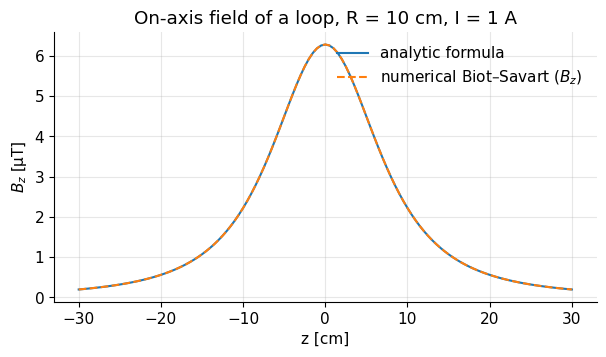

Field at the center: 6.28 uT per A  (mu0/(2R) = 6.28 uT/A)
max relative difference numeric vs analytic: 2.1e-04


In [3]:
R_c, I_c = 0.10, 1.0                            # 10 cm loop radius, 1 A
z = np.linspace(-0.3, 0.3, 121)                 # positions on the axis [m]
pts = np.stack([np.zeros_like(z), np.zeros_like(z), z], axis=-1)
B_num = mt.loop_coil_field(pts, R_c, I_c)       # numerical Biot-Savart, shape (121, 3)
B_ana = mt.loop_field_on_axis(z, R_c, I_c)      # analytic on-axis formula

plt.figure(figsize=(7, 3.5))
plt.plot(z * 100, B_ana * 1e6, label="analytic formula")
plt.plot(z * 100, B_num[:, 2] * 1e6, "--", label="numerical Biot–Savart ($B_z$)")
plt.xlabel("z [cm]"); plt.ylabel("$B_z$ [µT]"); plt.legend()
plt.title(f"On-axis field of a loop, R = {R_c*100:.0f} cm, I = {I_c:.0f} A")
plt.show()
print(f"Field at the center: {B_ana[60]*1e6:.2f} uT per A  (mu0/(2R) = {mt.MU0/(2*R_c)*1e6:.2f} uT/A)")
print(f"max relative difference numeric vs analytic: {np.max(np.abs(B_num[:,2]-B_ana))/B_ana.max():.1e}")

*Interpretation:* both agree (to ~10⁻⁴, the error of approximating the circle by 200 straight segments). One ampere in a 10 cm loop produces only ~6 µT — this number reappears as the RF coil sensitivity $B_1^-$ (µT/A).

### 2.2 Field map of a loop

Now the full vector field in a plane that contains the loop axis (port of the original's `loop_coil_field` example: a loop of radius 12 cm, current 3 A, lying in the $x$–$z$ plane so that its axis is $y$; we look at the $x$–$y$ plane). We use the fast vectorized `mt.loop_coil_field` instead of the original triple loop.

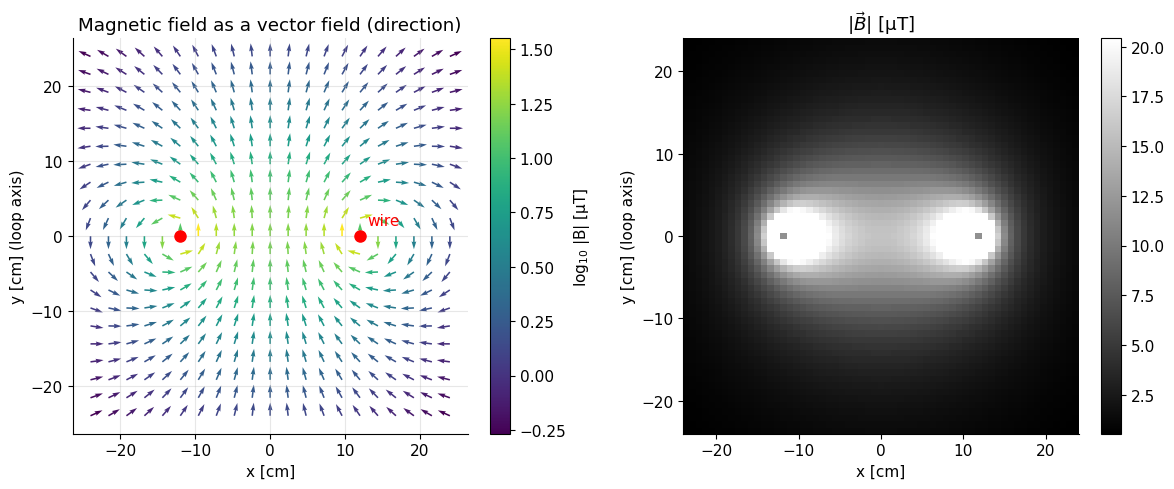

In [4]:
R_c, I_c = 0.12, 3.0                              # coil radius [m], current [A]
xp = np.linspace(-0.24, 0.24, 61)                # evaluation grid [m]
yp = np.linspace(-0.24, 0.24, 61)
X, Y = np.meshgrid(xp, yp)
P = np.stack([X, Y, np.zeros_like(X)], axis=-1)  # plane z = 0
B = mt.loop_coil_field(P, R_c, I_c, normal="y")  # loop in the x-z plane, axis along y
BX, BY, BZ = B[..., 0], B[..., 1], B[..., 2]
Bmag = np.sqrt(BX**2 + BY**2 + BZ**2)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
s = 3                                            # plot every 3rd arrow
# arrows show the field DIRECTION (unit length); their color shows log10 of the magnitude
U, Vv = BX / Bmag, BY / Bmag
q = ax[0].quiver(X[::s, ::s] * 100, Y[::s, ::s] * 100, U[::s, ::s], Vv[::s, ::s], np.log10(Bmag[::s, ::s] * 1e6),
                 cmap="viridis", scale=30, width=0.004)
plt.colorbar(q, ax=ax[0], fraction=0.046, label="log$_{10}$ |B| [µT]")
ax[0].plot([-R_c * 100, R_c * 100], [0, 0], "ro", ms=8)
ax[0].text(R_c * 100 + 1, 1.5, "wire", color="r")
ax[0].set_aspect("equal"); ax[0].set_xlabel("x [cm]"); ax[0].set_ylabel("y [cm] (loop axis)")
ax[0].set_title("Magnetic field as a vector field (direction)")
im = ax[1].imshow(Bmag * 1e6, extent=[xp[0] * 100, xp[-1] * 100, yp[0] * 100, yp[-1] * 100], origin="lower",
                  cmap="gray", vmax=np.percentile(Bmag, 97) * 1e6)
ax[1].set_xlabel("x [cm]"); ax[1].set_ylabel("y [cm] (loop axis)"); ax[1].grid(False)
ax[1].set_title("$|\\vec B|$ [µT]"); plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

*Interpretation:* the field lines go through the loop and close around the wires; the magnitude is largest near the wires and decays with distance on either side. If this loop is used as a receive coil placed *below* a patient, its sensitivity is "one-sided": high near the coil, low deep in the body (the original's "one-sided $B_1$ sensitivity profile").

## 3. Solenoids and the main magnet $B_0$

We can also link many loops together (a **solenoid**) to extend the region of strong field:

![Field of a solenoid](../images/solenoid_small_current.png)

*Field lines of a solenoid: inside, the lines are nearly parallel and equally spaced, i.e. the field is nearly uniform.*

A solenoid design is used for the main magnet of cylindrical MRI scanners because it creates a large region with a strong, nearly homogeneous field. For an infinitely long solenoid the field inside is exactly uniform:

$$B_0 = \mu_0\, n\, I_c$$

*In words:* the field grows with the number of turns per metre and with the current; it does not depend on the radius.
where $n$ = turns per metre [1/m], $I_c$ = current [A].
Example: 3 T with $I_c$ = 500 A needs $n = 3/(4\pi\times10^{-7}\cdot 500)\approx 4800$ turns per metre (in many layers) — roughly 20 km of superconducting wire for a 1.5 m long, 1 m diameter coil. See [B3](B3_Main_Magnet_Engineering.ipynb).

A real solenoid has finite length $L_s$; then the on-axis field is (sum of the loop formula over all turns)

$$B_z(z)=\frac{\mu_0 n I_c}{2}\left[\frac{z+L_s/2}{\sqrt{R_c^2+(z+L_s/2)^2}}-\frac{z-L_s/2}{\sqrt{R_c^2+(z-L_s/2)^2}}\right]$$

*In words:* the field is the infinite-solenoid value times a geometric factor ≤ 1 that drops towards the ends.
where $z$ = position along the axis measured from the center [m], $L_s$ = solenoid length [m], $R_c$ = radius [m].

### 3.1 Why $B_0$ must be homogeneous to a few ppm

The frequency of the spins is $f=\bar\gamma B$, so any field error $\Delta B_0$ is a frequency error $\Delta f=\bar\gamma\Delta B_0$. It causes:

* **geometric distortion**: in the readout direction a spin is mis-placed by $\Delta x = \Delta f / BW_{pix}$ pixels ([Artifacts](I2_Artifacts.ipynb));
* **signal loss** in gradient-echo images through intravoxel dephasing ($T_2^*$, see [In Vivo Spin Physics](A3_In_Vivo_Spin_Physics.ipynb));
* **failed fat suppression**: fat is only 3.5 ppm away from water, so a field error of ~1 ppm already shifts the fat-saturation pulse noticeably off target;
* **slice shifts/bending** in slice-selective excitation, and dark bands in bSSFP.

In [5]:
B0 = 3.0
BW_pix = 200.0                                    # typical readout bandwidth per pixel [Hz]
for ppm in [0.1, 1.0, 3.5, 10.0]:
    df = mt.ppm_to_hz(ppm, B0)                    # frequency error [Hz]
    print(f"{ppm:5.1f} ppm at {B0} T -> {df:7.1f} Hz -> readout shift {df/BW_pix:5.2f} pixels at {BW_pix:.0f} Hz/pixel")

  0.1 ppm at 3.0 T ->    12.8 Hz -> readout shift  0.06 pixels at 200 Hz/pixel
  1.0 ppm at 3.0 T ->   127.7 Hz -> readout shift  0.64 pixels at 200 Hz/pixel
  3.5 ppm at 3.0 T ->   447.1 Hz -> readout shift  2.24 pixels at 200 Hz/pixel
 10.0 ppm at 3.0 T ->  1277.3 Hz -> readout shift  6.39 pixels at 200 Hz/pixel


*Interpretation:* a 1 ppm error is already more than half a pixel of distortion; 10 ppm is a disaster. Clinical magnets are specified to a few ppm (peak-to-peak) over a 40–50 cm **DSV** (diameter of spherical volume), and sub-ppm after patient shimming in the region of interest.

How close does a simple solenoid get? Let's compute the field variation over a 50 cm DSV for a solenoid of radius 0.5 m and various lengths.

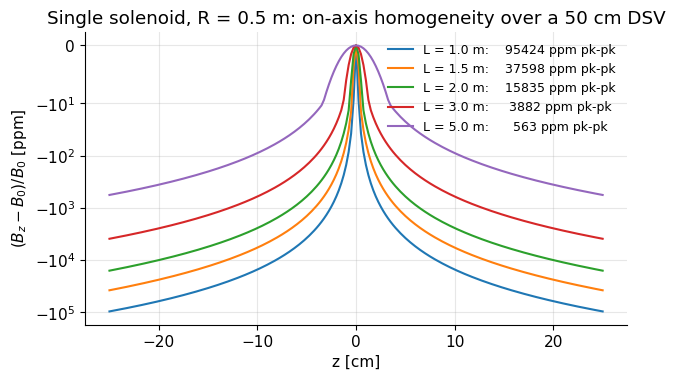

In [6]:
def solenoid_on_axis(z, R_c, L_s, n_I=1.0):
    """On-axis Bz [T] of a finite solenoid (n*I = n_I ampere-turns per metre)."""
    a, b = z + L_s / 2, z - L_s / 2
    return mt.MU0 * n_I / 2 * (a / np.sqrt(R_c**2 + a**2) - b / np.sqrt(R_c**2 + b**2))

R_c = 0.5
z = np.linspace(-0.25, 0.25, 201)                 # +-25 cm = 50 cm DSV along the axis
plt.figure(figsize=(7, 3.8))
for L_s in [1.0, 1.5, 2.0, 3.0, 5.0]:
    b = solenoid_on_axis(z, R_c, L_s)
    ppm = (b / b[100] - 1) * 1e6
    plt.plot(z * 100, ppm, label=f"L = {L_s} m: {ppm.max()-ppm.min():8.0f} ppm pk-pk")
plt.yscale("symlog", linthresh=10); plt.xlabel("z [cm]"); plt.ylabel("$(B_z-B_0)/B_0$ [ppm]")
plt.title("Single solenoid, R = 0.5 m: on-axis homogeneity over a 50 cm DSV"); plt.legend(fontsize=9)
plt.show()

*Interpretation:* even a 5 m long solenoid (impossible for patients) is ~500 ppm inhomogeneous over 50 cm — far from the few-ppm target. Real magnets therefore use **several coils with different currents** (some even reversed) whose errors cancel, plus shimming. [B3](B3_Main_Magnet_Engineering.ipynb) designs such a magnet in Python and reaches a few ppm with a 1.6 m long magnet.

### 3.2 The main field in the field vector

The main magnet creates fields of usually 1.5 or 3 T, by convention oriented in the $z$-direction, and this field is always on. Mathematically:

$$\vec{B}(\vec{r},t) = \begin{bmatrix} 0 \\ 0 \\ B_0 \end{bmatrix}$$

*In words:* the main field points along $z$ with the same magnitude everywhere (ideally) and does not change in time.

This field is never perfect, which is captured by the main field inhomogeneities, $\Delta B_0(\vec r)$ (so $B_z = B_0+\Delta B_0(\vec r)$), and the field experienced by a nucleus also changes with its molecular environment (**chemical shift**). These are described in [In Vivo Spin Physics](A3_In_Vivo_Spin_Physics.ipynb).

## 4. Magnetic field gradient coils — $\vec{G}(t)$

The gradient coils are designed to add to and subtract from the main field so that $B_z$ varies linearly with position. Since the resonance frequency is proportional to the field, the frequency then varies with position, which gives us a way to separate signals from different regions ([Spatial Encoding](F1_Spatial_Encoding.ipynb)).

Gradient fields have a maximum amplitude of around 40–80 mT/m (0.04–0.08 T/m) on clinical systems (up to 200–300 mT/m on special research "connectome" or head-only systems). They are switched on and off during the experiment: typically changing every few ms, with minimum ramp times of ~0.1–0.2 ms. Mathematically, we add them to the field vector:

$$\vec{B}(\vec{r},t) = \begin{bmatrix} 0 \\ 0 \\ B_0 + \vec{G}(t) \cdot \vec{r} \end{bmatrix}$$

*In words:* the gradients create linear changes in the $z$-component of the field across space; $\vec G\cdot\vec r = G_x x+G_y y+G_z z$.
where $\vec G(t)$ = gradient amplitudes [T/m], $\vec r$ = position [m].

> **⚠️ Common confusion:** "the $x$-gradient" does *not* create a field pointing along $x$. All three gradient coils produce (mainly) a $z$-directed field; $G_x$ means that $B_z$ *changes* along $x$. (We'll see in §4.3 that Maxwell's equations force small extra $x$/$y$ components — the concomitant fields.)

### 4.1 $G_z$: the Maxwell pair

Two loops of radius $R_c$ on the same axis, at $z=\pm d$, with **opposite** currents: their fields cancel at the center and $B_z$ increases linearly with $z$ between them. The linear region is best (the $z^3$ error term vanishes) for the **Maxwell spacing** $d=\frac{\sqrt3}{2}R_c$, i.e. a separation $2d=\sqrt3\,R_c$. (The Helmholtz pair, with the *same* current direction at a separation $R_c$, is the analogous design for a uniform field.)

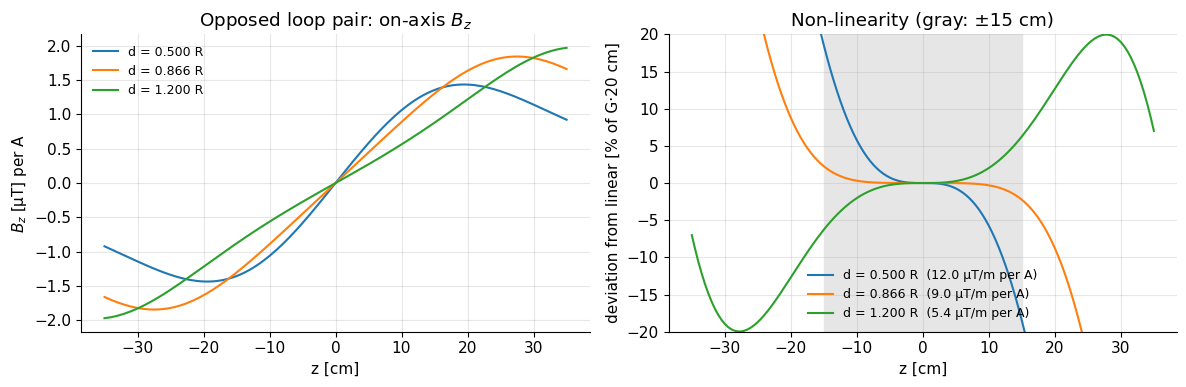

In [7]:
R_c = 0.30                                       # gradient coil radius [m] (clinical: ~0.3-0.35 m)
z = np.linspace(-0.35, 0.35, 141)
pts = np.stack([np.zeros_like(z), np.zeros_like(z), z], -1)

def maxwell_pair(points, R_c, d, I_c=1.0):
    """Bz field of two opposed loops at z=+d (current +I) and z=-d (current -I)."""
    return (mt.loop_coil_field(points, R_c, +I_c, center=(0, 0, +d))
            + mt.loop_coil_field(points, R_c, -I_c, center=(0, 0, -d)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for d_rel in [0.5, np.sqrt(3) / 2, 1.2]:
    Bz = maxwell_pair(pts, R_c, d_rel * R_c)[:, 2]
    G0 = np.gradient(Bz, z)[70]                   # gradient at the center [T/m per A]
    ax[0].plot(z * 100, Bz * 1e6, label=f"d = {d_rel:.3f} R")
    ax[1].plot(z * 100, (Bz - G0 * z) / (G0 * 0.2) * 100, label=f"d = {d_rel:.3f} R  ({G0*1e6:.1f} µT/m per A)")
ax[0].set_xlabel("z [cm]"); ax[0].set_ylabel("$B_z$ [µT] per A"); ax[0].set_title("Opposed loop pair: on-axis $B_z$")
ax[1].set_ylim(-20, 20); ax[1].axvspan(-15, 15, color="0.9")
ax[1].set_xlabel("z [cm]"); ax[1].set_ylabel("deviation from linear [% of G·20 cm]")
ax[1].set_title("Non-linearity (gray: ±15 cm)"); ax[1].legend(fontsize=9)
for a in ax: a.legend(fontsize=9)
plt.tight_layout(); plt.show()

*Interpretation:* with the Maxwell spacing $d=0.866R$ the field stays linear to ~1 % over about ±0.5 $R_c$ (±15 cm here); other spacings bend away much earlier. The efficiency is only ~9 µT/m per ampere for one turn, so a 40 mT/m gradient needs ~4500 ampere-turns — real coils use many turns and several hundred amperes ([B4](B4_Gradient_System_Engineering.ipynb)).

Here is the field of the Maxwell pair in the $x$–$z$ plane: contours of constant $B_z$ should be equally spaced straight lines (perpendicular to $z$) in the linear region.

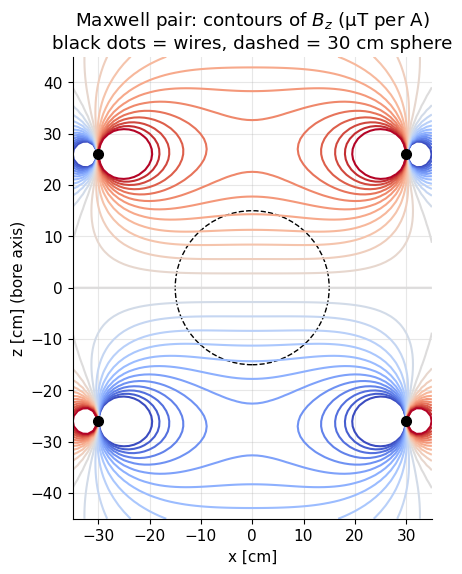

analytic Maxwell-pair efficiency 0.6413*mu0/R^2 = 8.95 uT/m per A


In [8]:
x = np.linspace(-0.35, 0.35, 71); zz = np.linspace(-0.45, 0.45, 91)
Xg, Zg = np.meshgrid(x, zz)
P = np.stack([Xg, np.zeros_like(Xg), Zg], -1)
Bz = maxwell_pair(P, R_c, np.sqrt(3) / 2 * R_c)[..., 2]
G0 = 0.6413 * mt.MU0 / R_c**2                     # analytic Maxwell-pair efficiency [T/m per A]
plt.figure(figsize=(6, 6))
cs = plt.contour(Xg * 100, Zg * 100, Bz * 1e6, levels=np.linspace(-3, 3, 25), cmap="coolwarm")
plt.plot([-30, 30, -30, 30], [26, 26, -26, -26], "ko", ms=7)
plt.gca().add_patch(plt.Circle((0, 0), 15, fill=False, ls="--", color="k"))
plt.xlabel("x [cm]"); plt.ylabel("z [cm] (bore axis)"); plt.gca().set_aspect("equal")
plt.title("Maxwell pair: contours of $B_z$ (µT per A)\nblack dots = wires, dashed = 30 cm sphere")
plt.show()
print(f"analytic Maxwell-pair efficiency 0.6413*mu0/R^2 = {G0*1e6:.2f} uT/m per A")

*Interpretation:* inside the dashed 30 cm sphere the contours are straight, parallel and evenly spaced (linear $G_z$); near the wires they curve. Gradient non-linearity at the edge of large FOVs is real and is corrected in reconstruction ("distortion correction", [B4](B4_Gradient_System_Engineering.ipynb)).

### 4.2 $G_x$ and $G_y$: saddle (Golay) coils

To make $B_z$ vary along $x$ we need a coil whose $z$-field is positive at $+x$ and negative at $-x$. Loops cannot do this on a cylinder; instead one uses four **saddle coils**, curved rectangles lying on the cylinder surface. In the classic **Golay** design each saddle has two arcs spanning 120°; the inner arcs (at $|z|=0.389\,R_c$) produce the gradient, the outer arcs (at $|z|=2.57\,R_c$) are far away and the return paths along $z$ produce no $B_z$ at all (a current parallel to $z$ creates a field perpendicular to $z$). $G_y$ is the same coil rotated by 90°. Modern coils use computer-optimized "fingerprint" windings ([B4](B4_Gradient_System_Engineering.ipynb)), but the principle is the same.

`mt.loop_coil_field` only handles circles, so we write a small general Biot–Savart helper for any polyline (same algorithm).

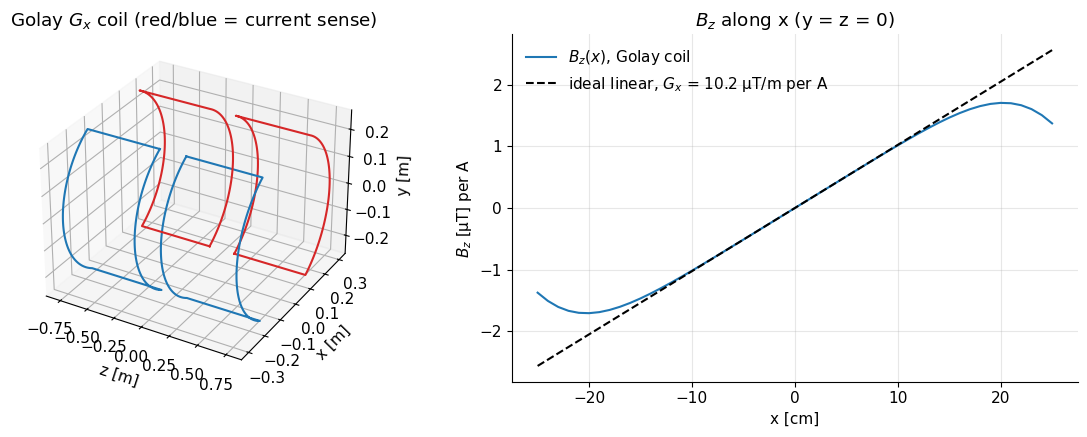

In [9]:
def wire_field(points, path, current=1.0):
    """Biot-Savart field [T] of a polyline wire `path` (K, 3) carrying `current` [A] at `points` (..., 3)."""
    pts = np.asarray(points, float); path = np.asarray(path, float)
    mid = 0.5 * (path[1:] + path[:-1]); dl = path[1:] - path[:-1]
    flat = pts.reshape(-1, 3); B = np.zeros_like(flat)
    for i in range(0, flat.shape[0], 2048):
        Rv = flat[i:i + 2048, None, :] - mid[None]
        Rn = np.maximum(np.linalg.norm(Rv, axis=-1, keepdims=True), 1e-6)
        B[i:i + 2048] = (mt.MU0 * current / (4 * np.pi) * np.cross(dl[None], Rv) / Rn**3).sum(1)
    return B.reshape(pts.shape)

def saddle(a, z1, z2, phi_c, span=np.deg2rad(120), n=60):
    """Closed saddle loop on a cylinder of radius a: arc at z1, axial segment, arc back at z2, axial segment."""
    ph = np.linspace(phi_c - span / 2, phi_c + span / 2, n)
    inner = np.stack([a * np.cos(ph), a * np.sin(ph), np.full(n, z1)], -1)
    outer = np.stack([a * np.cos(ph[::-1]), a * np.sin(ph[::-1]), np.full(n, z2)], -1)
    return np.vstack([inner, outer, inner[:1]])

a = 0.30                                            # cylinder radius [m]
golay = []                                          # list of (path, current sign)
for zs in (+1, -1):
    for phi_c, sign in ((0.0, +1), (np.pi, -1)):    # saddles centred at +x (current +) and -x (current -)
        golay.append((saddle(a, zs * 0.389 * a, zs * 2.57 * a, phi_c), sign))
B_golay = lambda p: sum(wire_field(p, path, s) for path, s in golay)

# 3D view of the windings and field along x
fig = plt.figure(figsize=(12, 4.5))
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
for path, s in golay:
    ax3.plot(path[:, 2], path[:, 0], path[:, 1], color="C3" if s > 0 else "C0")
ax3.set_xlabel("z [m]"); ax3.set_ylabel("x [m]"); ax3.set_zlabel("y [m]"); ax3.set_title("Golay $G_x$ coil (red/blue = current sense)")
x = np.linspace(-0.25, 0.25, 51)
Bx_line = B_golay(np.stack([x, 0 * x, 0 * x], -1))[:, 2]
Gx0 = np.gradient(Bx_line, x)[25]
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(x * 100, Bx_line * 1e6, label="$B_z(x)$, Golay coil")
ax2.plot(x * 100, Gx0 * x * 1e6, "k--", label=f"ideal linear, $G_x$ = {Gx0*1e6:.1f} µT/m per A")
ax2.set_xlabel("x [cm]"); ax2.set_ylabel("$B_z$ [µT] per A"); ax2.legend(); ax2.set_title("$B_z$ along x (y = z = 0)")
plt.tight_layout(); plt.show()

*Interpretation:* the four saddles produce a $B_z$ that is linear in $x$ near the center (and zero along the $z$-axis), i.e. a transverse gradient; efficiency is similar to the Maxwell pair, ~10 µT/m per ampere-turn at 30 cm radius. Linearity again degrades beyond ~±0.4–0.5 $R_c$.

### 4.3 Concomitant ("Maxwell") fields

A field with $B_z = B_0 + G_z z$ and *nothing else* is impossible: in a current-free region Maxwell's equations require $\nabla\cdot\vec B = 0$ and $\nabla\times\vec B = 0$. If $\partial B_z/\partial z = G_z$, then $\partial B_x/\partial x + \partial B_y/\partial y = -G_z$, so transverse field components must exist. For a cylindrically symmetric $G_z$ coil they are $B_x=-\tfrac12G_zx$, $B_y=-\tfrac12G_zy$. The spins precess about the **magnitude** of the total field:

$$|\vec B| = \sqrt{(B_0+G_z z)^2+\tfrac14 G_z^2(x^2+y^2)} \approx B_0 + G_z z + \frac{G_z^2}{8B_0}(x^2+y^2)$$

*In words:* on top of the intended linear term, there is a small quadratic "concomitant" field that grows with gradient strength squared and shrinks with $B_0$.
where $G_z$ = gradient [T/m], $x,y,z$ = position [m], $B_0$ = main field [T]. The approximation uses $\sqrt{A^2+\epsilon}\approx A+\epsilon/(2A)$ for small $\epsilon$. (Transverse gradients give analogous terms ∝ $G_x^2z^2/(2B_0)$.)

In [10]:
Gz = 40e-3                       # 40 mT/m
r_perp = 0.20                    # 20 cm off axis
for B0 in [0.064, 0.55, 1.5, 3.0, 7.0]:
    Bc = Gz**2 / (8 * B0) * r_perp**2            # concomitant field [T]
    print(f"B0 = {B0:5.3f} T: concomitant field at 20 cm = {Bc*1e6:7.2f} uT -> {mt.GAMMA_BAR*Bc:7.1f} Hz off-resonance")

B0 = 0.064 T: concomitant field at 20 cm =  125.00 uT ->  5322.1 Hz off-resonance
B0 = 0.550 T: concomitant field at 20 cm =   14.55 uT ->   619.3 Hz off-resonance
B0 = 1.500 T: concomitant field at 20 cm =    5.33 uT ->   227.1 Hz off-resonance
B0 = 3.000 T: concomitant field at 20 cm =    2.67 uT ->   113.5 Hz off-resonance
B0 = 7.000 T: concomitant field at 20 cm =    1.14 uT ->    48.7 Hz off-resonance


*Interpretation:* at 1.5–3 T the concomitant field causes tens to ~100 Hz of phase error at the FOV edge during strong gradients (relevant for phase-contrast flow imaging, EPI, spiral); at 0.55 T and below it becomes hundreds of Hz and must be corrected — one of the engineering challenges of the low-field revival.

## 5. Radiofrequency (RF) coils — $B_1^+(\vec{r},t)$, $B_1^-(\vec{r})$

The purposes of the RF coils and RF systems are

1. **Excitation** – perturb the net magnetization from equilibrium by creating magnetic fields at the resonance frequency
2. **Reception** – after excitation, the precessing net magnetization creates magnetic fields at the resonance frequency, which induce a voltage in the coil

These are called RF coils since the resonance frequencies for MRI, typically ~20–300 MHz (about 100 MHz), are in the radio-frequency range. All RF coils must be **tuned** to the resonance frequency to transmit and receive efficiently ([Induction and RF refresher](../refreshers/RP2_Induction_and_RF.ipynb), [B5](B5_RF_System_and_Receive_Chain.ipynb)).

Their amplitude is much smaller than the other fields, typically ~10 µT = 0.00001 T. The RF fields are oriented **perpendicular** to the main field, i.e. in the transverse ($x$–$y$) plane — a field component along $z$ would only modulate the precession frequency slightly and does not tip spins. In the **lab frame**:

$$\vec{B}(\vec{r},t) = \begin{bmatrix} B_{1,X}(\vec{r},t) \cos(\omega_0 t) + B_{1,Y}(\vec{r},t) \sin(\omega_0 t) \\ - B_{1,X}(\vec{r},t) \sin(\omega_0 t) + B_{1,Y}(\vec{r},t) \cos(\omega_0 t) \\ B_0 + \vec{G}(t) \cdot \vec{r} \end{bmatrix}, \qquad \omega_0 = 2\pi\bar\gamma B_0$$

*In words:* the transverse RF field is the vector $(B_{1,X},B_{1,Y})$ **rotated clockwise** by the angle $\omega_0 t$, i.e. it rotates at the Larmor frequency in the same (left-handed) sense as the spins precess. In the **rotating frame** (which turns with the spins) this rotation disappears, and we are left with a static transverse field with components $B_{1,X}$, $B_{1,Y}$, i.e. the complex envelope $b_1 = B_{1,X}+iB_{1,Y}$ used in `mt.bloch_simulate`.
where $B_{1,X}, B_{1,Y}$ = rotating-frame RF components [T] (slowly varying pulse envelope), $\omega_0$ = Larmor angular frequency [rad/s], $t$ = time [s].

> **⚠️ Common confusion (correction):** the original wrote the $B_{1,Y}$ terms with the opposite signs ($-B_{1,Y}\sin$ in $x$ and $-B_{1,Y}\cos$ in $y$). That expression is not a rotation of $(B_{1,X},B_{1,Y})$: at $t=0$ it would give $B_y=-B_{1,Y}$. The version above is the clockwise rotation $\vec B_{xy}=R_z(-\omega_0 t)\,[B_{1,X},B_{1,Y}]^T$, consistent with $M_{xy}(t)=M_{xy}(0)e^{-i\omega_0 t}$ in `mri_tools`. In complex notation: $B_x+iB_y = b_1\,e^{-i\omega_0 t}$.

The RF system is divided into **transmit** and **receive** paths. All components are tuned to the Larmor frequency, meaning they are most sensitive at this frequency; reactive components (capacitors and inductors) are used for tuning.

### 5.1 Transmit (Tx) system for excitation — $B_1^+(\vec{r},t)$
- Transmits high-power RF (10s of kW peak)
- Key requirement is **homogeneity**: the same field, hence the same flip angle, across the imaging FOV
- Usually a single large coil surrounding the entire FOV (the body coil)

### 5.2 Receive (Rx) system for reception — $B_1^-(\vec{r})$
- Receives small signals (nV per voxel, up to ~mV for the whole excited volume; computed below) arising from the body
- Key requirement is **high sensitivity**: detect small signals with the least noise
- Usually an **array** of smaller coil elements (also called channels) placed close around the body

### 5.3 Creating transmit RF fields

To create a transmit RF field, we put an oscillating current into a loop of wire. When this is done at the Larmor frequency, it creates RF excitation. Here at 1.5 T ($f_0$ = 63.9 MHz) for a 10 cm loop (port of the original cell, now with real units).

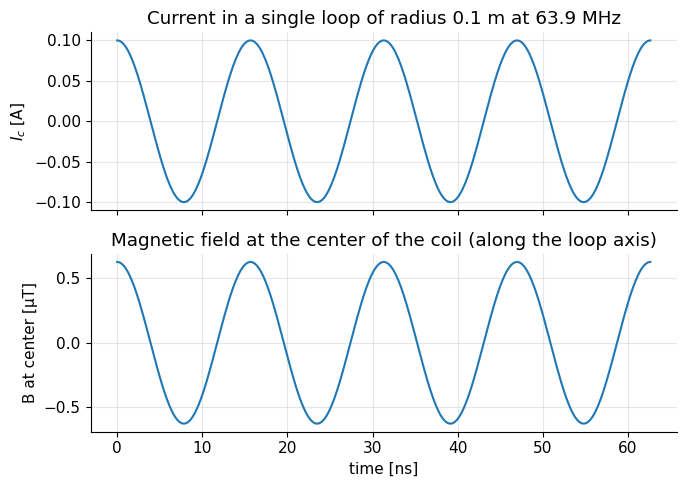

In [11]:
R_c = 0.1                     # coil radius [m]
I0 = 0.1                      # current amplitude [A]
f0 = mt.larmor_frequency(1.5) # 63.9 MHz
t = np.linspace(0, 4 / f0, 401)          # four RF periods [s]
I_t = I0 * np.cos(2 * np.pi * f0 * t)    # current [A]
Bz_center = mt.MU0 * I_t / (2 * R_c)     # field at the center of the loop [T], along the loop axis

fig, ax = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
ax[0].plot(t * 1e9, I_t); ax[0].set_ylabel("$I_c$ [A]")
ax[0].set_title(f"Current in a single loop of radius {R_c} m at {f0/1e6:.1f} MHz")
ax[1].plot(t * 1e9, Bz_center * 1e6); ax[1].set_ylabel("B at center [µT]")
ax[1].set_xlabel("time [ns]"); ax[1].set_title("Magnetic field at the center of the coil (along the loop axis)")
plt.tight_layout(); plt.show()

*Interpretation:* the field follows the current instantaneously (at these sizes, much smaller than the wavelength, the quasi-static Biot–Savart picture holds). 0.1 A gives only 0.6 µT; a 90° pulse in 1 ms needs ~5.9 µT *co-rotating* field, which is why RF amplifiers deliver tens of amperes into the body coil. Note that this loop's field is along *its own axis*, so for excitation the loop axis must be **perpendicular** to $B_0$.

### 5.4 Linear vs circular polarization

A single loop produces a **linearly polarized** field: it oscillates back and forth along one direction, $\vec B_{xy}(t)=2B_1\cos(\omega_0 t)\,\hat x$. Any linear oscillation is the sum of **two counter-rotating** fields of half the amplitude:

$$2B_1\cos(\omega_0 t)\,\hat x = \underbrace{B_1\begin{bmatrix}\cos\omega_0 t\\ -\sin\omega_0 t\end{bmatrix}}_{\text{clockwise: co-rotating with spins}} + \underbrace{B_1\begin{bmatrix}\cos\omega_0 t\\ +\sin\omega_0 t\end{bmatrix}}_{\text{counter-clockwise}}$$

*In words:* only the component rotating **with** the spins (here clockwise) looks static in the rotating frame and tips the magnetization — this is $B_1^+$. The other component rotates at $-2\omega_0$ relative to the spins and averages out; it does no useful work but still deposits RF power (heating) in the patient.
where $B_1$ = amplitude of each rotating component [T], $\hat x$ = unit vector along $x$.

A **quadrature** (circularly polarized) coil uses two coils at 90° to each other (or the two orthogonal modes of a birdcage), driven 90° out of phase, to create only the co-rotating field. For the same $B_1^+$:

* linear: one coil must make $2B_1$ → current $\propto 2B_1$ → power $\propto (2B_1)^2 = 4B_1^2$;
* quadrature: two coils each make $B_1$ → power $\propto 2\times B_1^2 = 2B_1^2$.

So quadrature needs **half the RF power** (and half the SAR from the useless component); by reciprocity, in reception it gives $\sqrt2$ better SNR.

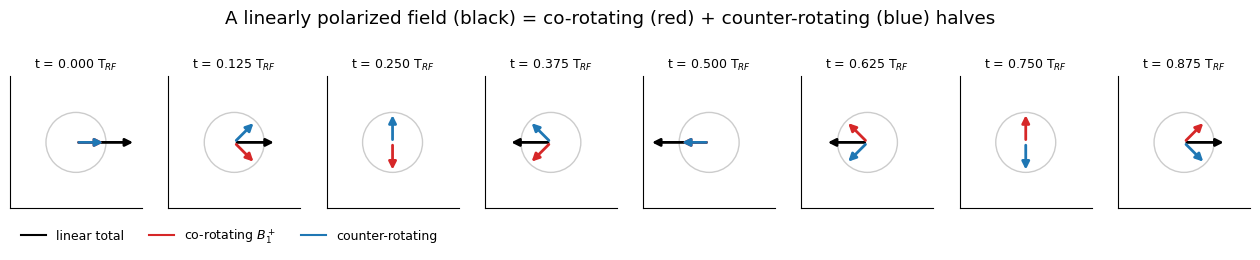

In [12]:
w = 2 * np.pi                               # one period = 1 (time in RF periods)
tt = np.linspace(0, 1, 9)[:-1]              # 8 snapshots in one RF period
fig, axs = plt.subplots(1, 8, figsize=(16, 2.4))
for ax_, ti in zip(axs, tt):
    lin = np.array([2 * np.cos(w * ti), 0])               # linear field 2 B1 cos(wt) x
    cw = np.array([np.cos(w * ti), -np.sin(w * ti)])       # co-rotating (clockwise) part
    ccw = np.array([np.cos(w * ti), np.sin(w * ti)])       # counter-rotating part
    for v, col, lab in [(lin, "k", "linear total"), (cw, "C3", "co-rotating $B_1^+$"), (ccw, "C0", "counter-rotating")]:
        ax_.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
        ax_.plot([], [], color=col, label=lab)
    ax_.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.8"))
    ax_.set_xlim(-2.2, 2.2); ax_.set_ylim(-2.2, 2.2); ax_.set_aspect("equal"); ax_.set_xticks([]); ax_.set_yticks([])
    ax_.set_title(f"t = {ti:.3f} T$_{{RF}}$", fontsize=9)
axs[0].legend(loc="upper left", bbox_to_anchor=(0, -0.05), ncol=3, fontsize=9)
plt.suptitle("A linearly polarized field (black) = co-rotating (red) + counter-rotating (blue) halves", y=1.05)
plt.show()

*Interpretation:* the black arrow only swings along $x$, but it is always the sum of the red arrow (turning clockwise, like the spins) and the blue arrow (turning counter-clockwise). Only the red half tips spins.

### 5.5 Receiving the magnetic resonance signal

The MR signal is received by the following sequence of events:

1. Spins and the net magnetization, $\vec{M}$, precess in the magnetic field at the Larmor frequency $f_0 = \bar{\gamma} B_0$.
2. This precession creates an oscillating magnetic field at the same (Larmor) frequency.
3. An oscillating magnetic flux through a loop of wire induces an oscillating voltage (Faraday's law), which is amplified and digitized.

![RF reception: precessing magnetization induces a current in a coil](../images/RF_reception.gif)

*Animation: the precessing magnetization (rotating arrow) produces a changing flux through the coil loop, which induces an oscillating signal.*

### 5.6 Reciprocity

The principle of **reciprocity** in electromagnetism says that the same geometric relationship governs (a) creating a magnetic field with a current in a coil, and (b) the voltage induced in that coil by a magnetic source. Concretely: if a current $I_c$ in the coil would create a field $\vec B_c(\vec r)$ at position $\vec r$, then a small magnetic moment $\vec m$ at $\vec r$ produces a flux through the coil of

$$\Phi = \frac{\vec B_c(\vec r)}{I_c}\cdot\vec m$$

*In words:* the coil "sees" a magnetic source exactly as strongly as the coil would produce field at that source's location. The coil's field per unit current is therefore its **receive sensitivity**, $B_1^-(\vec r)$.
where $\Phi$ = magnetic flux through the coil [Wb = T m²], $\vec B_c/I_c$ = coil field per unit current [T/A], $\vec m=\vec M V$ = magnetic moment of a voxel of volume $V$ [A m²].

For precessing transverse magnetization, $\Phi$ oscillates at $\omega_0$, and Faraday's law $\mathcal E=-d\Phi/dt$ gives a voltage amplitude

$$|\mathcal E| = \omega_0\,\frac{|B_{c,xy}(\vec r)|}{I_c}\,M_{xy}\,V$$

*In words:* the induced voltage grows with frequency (hence with $B_0$), with the coil's transverse sensitivity at the voxel, and with the transverse magnetic moment.
where $\mathcal E$ = induced voltage (EMF) [V], $\omega_0$ = Larmor angular frequency [rad/s], $B_{c,xy}$ = transverse part of the coil's field [T], $M_{xy}$ = transverse magnetization [A/m], $V$ = voxel volume [m³]. Only the transverse part of the coil field matters, because the precessing moment lies in the $x$–$y$ plane. (For a circularly polarized coil the exact expression uses the counter-rotating component $B_1^-$; for a linear coil it reduces to this.)

Let's put in numbers: a 1 mm³ voxel of water at 3 T, fully excited, 5 cm deep in front of a 5 cm radius surface coil.

In [13]:
B0 = 3.0
w0 = 2 * np.pi * mt.larmor_frequency(B0)               # [rad/s]
M0 = N_H * (mt.GAMMA * mt.HBAR) ** 2 * B0 / (4 * mt.K_BOLTZMANN * T_body)   # [A/m]
R_c, depth = 0.05, 0.05                                # coil radius, voxel depth on the coil axis [m]
# transverse sensitivity: coil axis is perpendicular to B0, so its on-axis field is transverse
sens = mt.loop_field_on_axis(depth, R_c, 1.0)          # [T/A]
V_vox = 1e-9                                           # 1 mm^3 [m^3]
emf_vox = w0 * sens * M0 * V_vox
print(f"coil sensitivity at {depth*100:.0f} cm depth: {sens*1e6:.2f} uT/A")
print(f"EMF from one 1 mm^3 voxel: {emf_vox*1e9:.0f} nV")
V_slice = 0.005 * 0.2 * 0.2                            # 5 mm slice through a 20 x 20 cm head [m^3]
print(f"EMF if a whole 5 mm slice were in phase (echo peak, same sensitivity): {emf_vox * V_slice / V_vox * 1e3:.1f} mV")
# thermal noise for comparison: sqrt(4 k T R df), R = loaded coil resistance
R_noise, df = 2.0, 100e3                               # [ohm], [Hz]
print(f"thermal noise, {R_noise} ohm, {df/1e3:.0f} kHz bandwidth: {np.sqrt(4*mt.K_BOLTZMANN*T_body*R_noise*df)*1e9:.0f} nV rms")

coil sensitivity at 5 cm depth: 4.44 uT/A
EMF from one 1 mm^3 voxel: 33 nV
EMF if a whole 5 mm slice were in phase (echo peak, same sensitivity): 6.7 mV
thermal noise, 2.0 ohm, 100 kHz bandwidth: 59 nV rms


*Interpretation:* a single voxel contributes only tens of nanovolts — below the noise of a single sample. Images are nevertheless possible because each voxel's signal is present in *every* k-space sample (tens of thousands of them), and the Fourier reconstruction adds them coherently while noise adds incoherently ([SNR](G2_Signal_to_Noise_Ratio.ipynb)). The echo peak of a whole slice reaches ~mV, which sets the receiver gain ([B1](B1_MRI_System.ipynb)).

## 6. Transmit and receive RF coils

### 6.1 Transmit (Tx) RF coils
- Typically the built-in "**BODY**" coil
- **Birdcage** design: two end rings connected by many straight "rungs", with capacitors that make it resonate at $f_0$
- Provides a homogeneous field amplitude over a large volume
- Creates magnetic fields perpendicular to $B_0$

In MRI we denote the transmitted RF field as

$$B_1^+(\vec{r},t)$$

*In words:* the co-rotating transverse RF field that tips spins, varying over space $\vec r$ and time $t$.
This field is typically in the range of **microtesla** (µT; the original wrote millitesla, which is ~1000× too large: a 90° pulse of 1 ms needs only 5.9 µT).

![The body coil (birdcage) built into the bore of a scanner](../images/BODY_coil.png)

*The body coil: a large birdcage resonator inside the bore lining, used for transmission (and sometimes reception).*

![Birdcage coil schematic](../images/Birdcage_schematic.png)

*Birdcage schematic: rungs parallel to $B_0$ connecting two end rings, with capacitors. At resonance the rung currents vary as $\cos\varphi$ around the circumference.*

### 6.2 Receive (Rx) RF coils
- Tailored to the anatomy of interest, e.g. knee coils, abdomen coils, head coils
- Configured in arrays ("phased arrays")
- 8 to 64 individual coil elements (channels) in an array coil are common (up to 128 in research)
- Elements must be **decoupled** so they do not interfere with each other (overlap, preamplifier decoupling; [B5](B5_RF_System_and_Receive_Chain.ipynb))
- Tuned to the Larmor frequency when receiving signals
- **Detuned** (switched off) while transmit RF is active, so they don't distort the transmit field or get damaged
- *Goal: high sensitivity, by placing the elements as close as possible to the body*

In MRI we denote the sensitivity profile of receive element $n$ as

$$B_{1,n}^-(\vec{r})$$

*In words:* how strongly coil element $n$ "sees" magnetization at position $\vec r$ (its field per unit current, by reciprocity).
This sensitivity is typically of order **µT/A** (the original wrote mT/A; a 10 cm loop gives 6 µT/A at its center), and varies over space and between elements of the array. (It does not depend on time during reception, which is why we drop the $t$ argument.)

Some RF coils are also built into the patient table. In the picture below, array coils are placed on top of the subject and there are also coils in the table.

![Receive array coils placed on and under the patient](../images/TIM_receive_array.png)

*Receive arrays: flexible anterior arrays on the body and posterior (spine) arrays built into the table, together covering the whole body.*

## 7. RF coil profiles

### 7.1 Receive elements

Coil elements are most sensitive to signals originating near the element, and the sensitivity falls off as we move away from the coil. The following images show that each element is most sensitive, i.e. produces the brightest image, closest to itself:

![Images from individual elements of a spine array](../images/SpineArray.png)

*Images from individual elements of a spine array: each element only "sees" the anatomy close to it.*

A combined image is created from the multiple receive elements. This is typically done by **root-sum-of-squares** (rSoS): the square root of the sum of the squared element-image magnitudes, $\sqrt{\sum_n |m_n(\vec r)|^2}$. More SNR-optimal combinations are possible when the element sensitivities $C_n(\vec r)$ are known (Roemer combination; [Advanced SNR](J4_Advanced_SNR.ipynb)).

### 7.2 Which field components matter

Only the field component **perpendicular to $B_0$** can tip or detect spins. The simulation below compares the transverse sensitivity $|B_{xy}|$ (with $B_0$ along $z$) of the same 6 cm loop in the axial plane with its axis along $y$ (perpendicular to $B_0$) vs along $z$ (parallel to $B_0$).

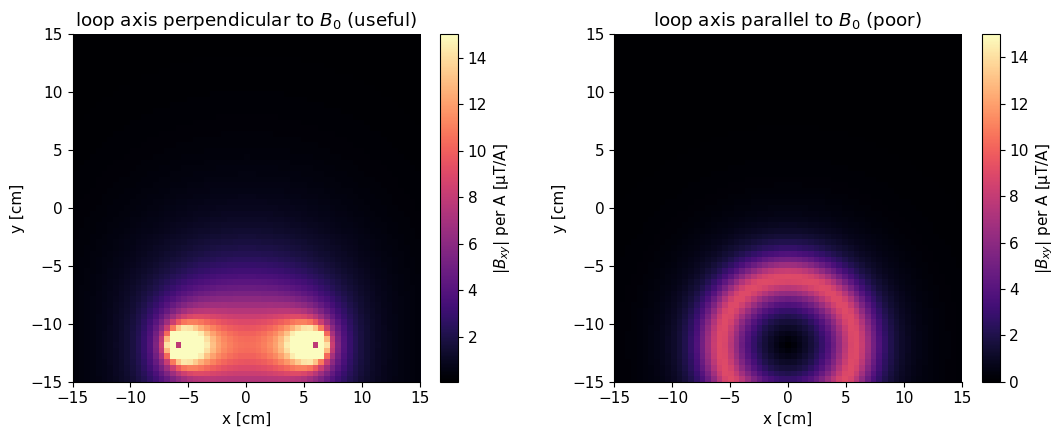

In [14]:
g = np.linspace(-0.15, 0.15, 61)
Xg, Yg = np.meshgrid(g, g)
P = np.stack([Xg, Yg, np.zeros_like(Xg)], -1)           # axial plane z = 0 [m]
R_loop = 0.06
loop_y = mt.loop_coil_field(P, R_loop, 1.0, center=(0, -0.12, 0), normal="y")   # axis perpendicular to B0
loop_z = mt.loop_coil_field(P, R_loop, 1.0, center=(0, -0.12, -0.02), normal="z")  # axis || B0, 2 cm below plane
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a_, B_, ttl in [(ax[0], loop_y, "loop axis perpendicular to $B_0$ (useful)"), (ax[1], loop_z, "loop axis parallel to $B_0$ (poor)")]:
    Bt = np.hypot(B_[..., 0], B_[..., 1]) * 1e6             # transverse magnitude [uT/A]
    im = a_.imshow(Bt, extent=[g[0]*100, g[-1]*100, g[0]*100, g[-1]*100], origin="lower", cmap="magma", vmax=15)
    a_.set_title(ttl); a_.set_xlabel("x [cm]"); a_.set_ylabel("y [cm]"); a_.grid(False)
    plt.colorbar(im, ax=a_, fraction=0.046, label="$|B_{xy}|$ per A [µT/A]")
plt.tight_layout(); plt.show()

*Interpretation:* the loop whose axis is perpendicular to $B_0$ has a strong transverse sensitivity that penetrates into the object. The loop lying flat with its axis along $B_0$ mainly produces $B_z$, which is useless; its transverse field is weak and exactly zero on its axis. Surface coils are therefore always oriented with their axis perpendicular to $B_0$ (for a patient in a horizontal bore: coils lying on the body, axis vertical).

### 7.3 Surface loop vs birdcage volume coil

To compare a surface loop with a birdcage we use a 2D cross-section model: long straight wires parallel to $z$ (the rungs), each creating $\vec B = \frac{\mu_0 I_c}{2\pi \rho}\hat\varphi$ around itself (field of an infinite straight wire, [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb)). This is a quasi-static model: it ignores wave effects in tissue, which become important at 3 T and above ([B5](B5_RF_System_and_Receive_Chain.ipynb)).

* **Birdcage:** 16 rungs on a circle of radius 30 cm with rung currents $I_n=\cos\varphi_n$ (linear mode) or the complex phasors $I_n=e^{i\varphi_n}$ (quadrature mode, two linear modes 90° apart in space *and* time).
* **Surface loop:** two antiparallel wires 10 cm apart below the object (a long rectangular loop).

For a field oscillating as $\mathrm{Re}\{(\tilde B_x\hat x+\tilde B_y\hat y)e^{i\omega t}\}$ the clockwise (co-rotating, for our left-handed precession) component has amplitude $|B_1^+| = \tfrac12|\tilde B_x - i\tilde B_y|$ and the counter-clockwise one $|B_1^-| = \tfrac12|\tilde B_x + i\tilde B_y|$ (derivation: write $\cos$ and $\sin$ as sums of $e^{\pm i\omega t}$, [complex refresher](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)). Sign conventions for $B_1^\pm$ differ between textbooks; what matters is that one component tips spins and the other does not.

birdcage, linear      : B1+ at center =   2.67 uT/A, B1- at center =   2.67 uT/A, B1+ per sqrt(power) =  0.94 (rel.)
birdcage, quadrature  : B1+ at center =   5.33 uT/A, B1- at center =   0.00 uT/A, B1+ per sqrt(power) =  1.33 (rel.)
surface loop (below)  : B1+ at center =   0.20 uT/A, B1- at center =   0.20 uT/A, B1+ per sqrt(power) =  0.14 (rel.)


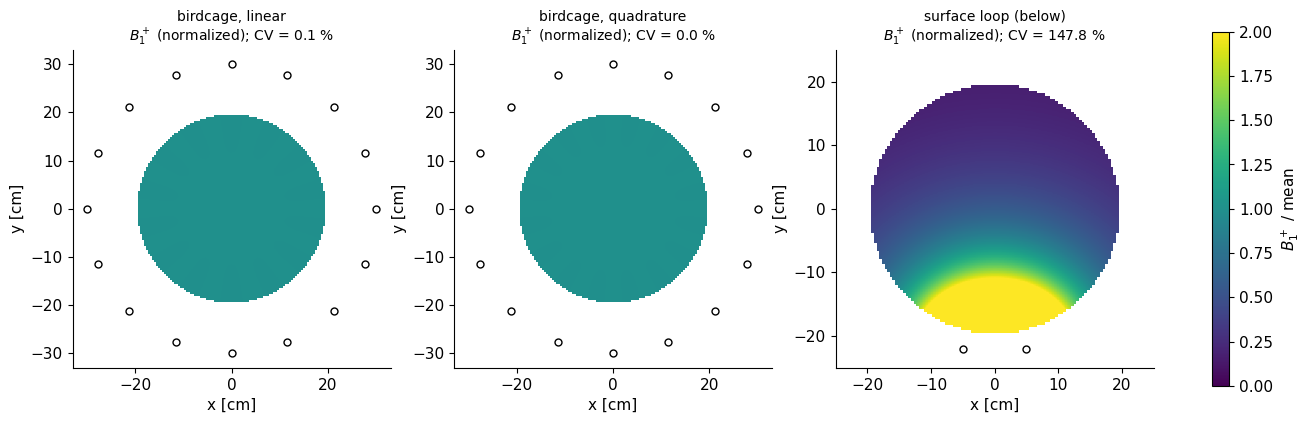

In [15]:
def wires_2d(X, Y, xs, ys, I):
    """Transverse field phasors (Bx, By) [T] of infinite straight wires along z at (xs, ys) with currents I [A]."""
    Bx = np.zeros_like(X, dtype=complex); By = np.zeros_like(X, dtype=complex)
    for xn, yn, In in zip(xs, ys, I):
        dx, dy = X - xn, Y - yn
        r2 = np.maximum(dx**2 + dy**2, 1e-6)
        Bx += mt.MU0 * In / (2 * np.pi) * (-dy) / r2
        By += mt.MU0 * In / (2 * np.pi) * (dx) / r2
    return Bx, By

g = np.linspace(-0.25, 0.25, 121); Xg, Yg = np.meshgrid(g, g)
inside = Xg**2 + Yg**2 < 0.2**2                        # 40 cm diameter "body"
Nr, Rbc = 16, 0.30
phi_n = 2 * np.pi * np.arange(Nr) / Nr
cases = {
    "birdcage, linear": (Rbc * np.cos(phi_n), Rbc * np.sin(phi_n), np.cos(phi_n)),
    "birdcage, quadrature": (Rbc * np.cos(phi_n), Rbc * np.sin(phi_n), np.exp(1j * phi_n)),
    "surface loop (below)": (np.array([-0.05, 0.05]), np.array([-0.22, -0.22]), np.array([1.0, -1.0])),
}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a_, (name, (xs, ys, I)) in zip(ax, cases.items()):
    Bx, By = wires_2d(Xg, Yg, xs, ys, I)
    Bp = 0.5 * np.abs(Bx - 1j * By)                    # co-rotating component per unit current [T/A]
    Bm = 0.5 * np.abs(Bx + 1j * By)                    # counter-rotating component
    P_rel = np.sum(np.abs(I) ** 2)                     # relative drive power ~ sum |I_n|^2 (equal rung resistance)
    eff = Bp[60, 60] / np.sqrt(P_rel)                  # B1+ at center per sqrt(power)
    show = np.where(inside, Bp / Bp[inside].mean(), np.nan)
    im = a_.imshow(show, extent=[g[0]*100, g[-1]*100, g[0]*100, g[-1]*100], origin="lower", cmap="viridis", vmin=0, vmax=2)
    a_.plot(xs * 100, ys * 100, "wo", ms=5, mec="k")
    a_.set_title(f"{name}\n$B_1^+$ (normalized); CV = {Bp[inside].std()/Bp[inside].mean()*100:.1f} %", fontsize=10)
    a_.set_xlabel("x [cm]"); a_.set_ylabel("y [cm]"); a_.grid(False)
    print(f"{name:22s}: B1+ at center = {Bp[60,60]*1e6:6.2f} uT/A, B1- at center = {Bm[60,60]*1e6:6.2f} uT/A, "
          f"B1+ per sqrt(power) = {eff*1e6:5.2f} (rel.)")
plt.colorbar(im, ax=ax, fraction=0.02, label="$B_1^+$ / mean")
plt.show()

*Interpretation:* both birdcage modes are extremely uniform inside (coefficient of variation CV ≪ 1 % in this quasi-static model), whereas the surface loop's sensitivity falls steeply with distance — perfect for receiving from nearby tissue, useless for uniform excitation. The printed numbers confirm the polarization argument: the linear birdcage produces equal co- and counter-rotating parts, the quadrature birdcage produces only $B_1^+$; per unit of drive power, quadrature gives $\sqrt2$ more $B_1^+$, i.e. it needs **half the power** for the same flip angle.

### 7.4 A receive array and sum-of-squares combination

Finally, four loop elements around a 30 cm "body" (each with its axis pointing to the center, i.e. perpendicular to $B_0$), their individual transverse sensitivities $|B_{xy,n}|$, and the rSoS combination $\sqrt{\sum_n |B_{xy,n}|^2}$ (the relative intensity you would see in a uniform object).

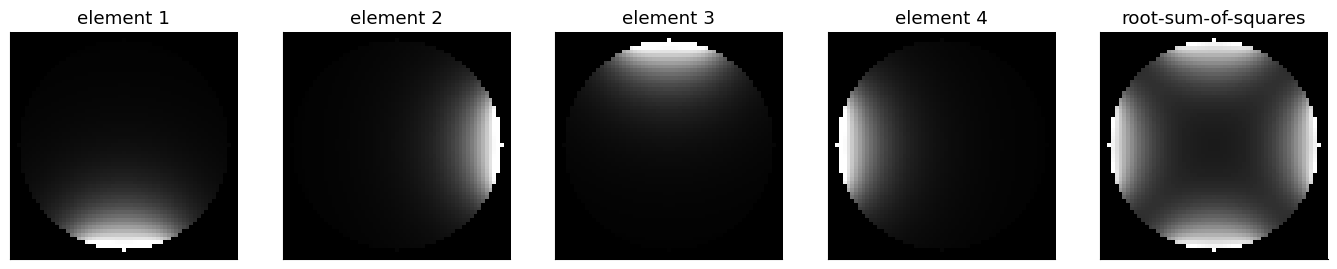

rSoS: edge / center intensity ratio = 9.9


In [16]:
g = np.linspace(-0.15, 0.15, 61); Xg, Yg = np.meshgrid(g, g)
P = np.stack([Xg, Yg, np.zeros_like(Xg)], -1)
elements = [((0, -0.16, 0), "y"), ((0.16, 0, 0), "x"), ((0, 0.16, 0), "y"), ((-0.16, 0, 0), "x")]
sens = []
for center, normal in elements:
    B_ = mt.loop_coil_field(P, 0.06, 1.0, center=center, normal=normal)
    sens.append(np.hypot(B_[..., 0], B_[..., 1]))      # transverse sensitivity [T/A]
sens = np.array(sens)
sos = np.sqrt(np.sum(sens**2, axis=0))
inside = Xg**2 + Yg**2 < 0.14**2
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for i in range(4):
    mt.show_image(np.flipud(np.where(inside, sens[i], 0)), ax=ax[i], title=f"element {i+1}", vmax=np.percentile(sens[:, inside], 99))
mt.show_image(np.flipud(np.where(inside, sos, 0)), ax=ax[4], title="root-sum-of-squares", vmax=np.percentile(sos[inside], 99))
plt.show()
print(f"rSoS: edge / center intensity ratio = {sos[inside].max()/sos[30,30]:.1f}")

*Interpretation:* (images shown with $+y$ up; element 1 is at the bottom) each element sees only its own quadrant (as in the spine-array images); the combined image covers the whole object but is brighter at the edges than at the center. This is why scanners apply an **intensity correction** (prescan normalize) using a measured sensitivity map, and why arrays with many small elements give a large SNR gain near the surface but only a modest one in the center.

> **🔧 Engineering reality:** the quasi-static models above are accurate at ≤ 1.5 T. At 3 T the RF wavelength in tissue (~30 cm) is comparable to the body and at 7 T (~12 cm) it is much smaller, so $B_1^+$ develops bright and dark regions ("dielectric effect"), even for a perfect birdcage. Remedies — dielectric pads, parallel transmission with multiple independently driven coils — are discussed in [B5](B5_RF_System_and_Receive_Chain.ipynb).

## Key takeaways

* All MRI fields can be computed from their currents with **Biot–Savart** and superposition; a loop gives $\mu_0 I_c/(2R_c)$ at its center (≈6 µT/A for 10 cm).
* $B_0$ comes from a solenoid-like magnet; it must be homogeneous to a few **ppm** over a 40–50 cm DSV because 1 ppm at 3 T is 128 Hz — more than half a pixel of distortion. A single solenoid is far worse; real magnets combine several coils ([B3](B3_Main_Magnet_Engineering.ipynb)).
* Gradient coils make $B_z$ vary linearly: a **Maxwell pair** (spacing $\sqrt3R_c$, opposite currents) for $G_z$, **saddle/Golay** coils for $G_x,G_y$; linear over roughly ±0.5 $R_c$.
* Maxwell's equations force **concomitant fields** ∝ $G^2/B_0$: negligible-ish at 3 T, significant at low field.
* RF fields must be **perpendicular to $B_0$**; only the **co-rotating** component $B_1^+$ tips spins. A linear coil wastes half its field; **quadrature** drive halves the power and gives $\sqrt2$ SNR on receive.
* By **reciprocity**, a coil's field per unit current is its receive sensitivity $B_1^-$; the induced voltage is $\omega_0 B_1^- M_{xy} V$ — nV per voxel, mV for a whole slice.
* Birdcage volume coils give uniform $B_1^+$; small surface loops give high but rapidly decaying sensitivity, so arrays + rSoS are used for reception.

## Check your understanding

1. A 30 cm radius Maxwell pair has an efficiency of ~9 µT/m per ampere-turn. How many ampere-turns are needed for 40 mT/m?

<details><summary>Answer</summary>

$40\times10^{-3}/(9\times10^{-6})\approx 4400$ ampere-turns, e.g. 10 turns at 440 A per coil. (Real coils use distributed windings, shielding coils, and smaller radius for better efficiency; see B4.)

</details>

2. Why does a loop lying flat on the patient table (axis vertical) work as a receive coil in a horizontal-bore scanner, while the same loop wrapped around the patient's leg like a ring (axis along the bore) does not?

<details><summary>Answer</summary>

In a horizontal bore $B_0$ is along the bore ($z$). A flat loop with a vertical axis produces a transverse field (perpendicular to $B_0$): good. A ring around the leg has its axis along $z$; its field inside is mainly $B_z$, which neither tips nor detects transverse magnetization. (Ring-shaped/solenoid coils around a limb work in *vertical-field* open magnets.)

</details>

3. What is the concomitant field 20 cm off-axis for $G_z$ = 80 mT/m at 0.55 T, in Hz?

<details><summary>Answer</summary>

$G_z^2 r^2/(8B_0)=(0.08)^2(0.2)^2/(8\cdot0.55)=5.8\times10^{-5}$ T → $\bar\gamma\cdot$ that ≈ 2.5 kHz. Very significant; it must be corrected (or the sequence designed to cancel it).

</details>

4. A linear body coil needs 16 kW to achieve a certain flip angle. Roughly how much would the same coil driven in quadrature need?

<details><summary>Answer</summary>

About 8 kW: the quadrature coil does not create the useless counter-rotating component, so half the power suffices for the same $B_1^+$ (and the SAR is halved).

</details>

5. Why are the individual receive-element images bright near the element and dark far away, and what does rSoS do about it?

<details><summary>Answer</summary>

By reciprocity the element's sensitivity is its field per unit current, which falls rapidly with distance from a small loop (roughly as $1/\text{distance}^3$ far away). rSoS combines all elements so every region is covered by the element(s) closest to it; the result is still inhomogeneous (bright edges) and is usually normalized using a sensitivity map.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Magnetic Fields in MRI". Changes: replaced the slow `loop_coil_field` script with `mt.loop_coil_field`, added Biot–Savart derivation, solenoid homogeneity and ppm requirements, Maxwell-pair and Golay gradient-coil simulations, concomitant fields, linear vs circular polarization, birdcage vs surface-coil and array/rSoS simulations, and an induced-EMF estimate; corrected the left-hand rule (→ right-hand rule), the sign of the $B_{1,Y}$ terms in the lab-frame RF field, units of the gradient (mT/m), $B_1^+$ (µT, not mT) and $B_1^-$ (µT/A, not mT/A), the magnetization field (≈10 nT, not 1 pT), and the receive signal level.*